In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def I_1(x, y, M, delta_x, delta_y, nx, ny):
    C0 = np.zeros((nx+1, ny+1))
    C0[len(x) // 2, len(y)//2] = M / (delta_x*delta_y)     # at x==0
    
    return C0

In [20]:
def solve_forward_2D(D, mass, Lx, Ly, T=200, N=20000, density = 1, plot_at_t =0):
    nx = density *Lx
    ny = density *Ly

    if nx %2 !=0: 
        nx += 1
    if ny%2!=0:
        ny += 1
    t = np.linspace(0.0, T, N + 1)          # Time grid
    x = np.linspace(-Lx, Lx, nx + 1)        # space-x grid
    y = np.linspace(-Ly, Ly, ny + 1)        # space-y grid

    dx = x[1]-x[0]
    dt = t[1]-t[0]
    dy = y[1]-y[0]

    # CHECK STABILITY CONDITION 
    # rx + ry <= 0.5
    rx = D*dt/dx**2
    ry = D*dt/dy**2

    if rx+ry>0.5:
        print("UNSTABLE !!!", rx+ry)
        return None, None, None
        
    else:
        u = np.zeros((N+1, nx+1, ny+1))

        # For the boundary conditions:
        # we have C(-Lx, y, t)=C(-Lx, y, t)=C(x, -Ly, t)=C(x, Ly, t)=0

        u[:, :, 0] = np.zeros((N+1,nx+1)) 
        u[:, :, -1] = np.zeros((N+1, nx+1))
        u[: ,0, :] = np.zeros((N+1,ny+1))
        u[: ,-1, :] = np.zeros((N+1, ny+1))


        # our initial conditions
        # first, we have at t = 0
        # C(t, x, y) = M delta(x) * delta(y)
        u[0, :, :] = I_1(x, y, mass, dx, dy, nx, ny)

    
        for k in range(0, N):
            """for i in range(1, nx):
                for j in range(1, ny):
                    uxx = (u[k,i+1,j] - 2*u[k,i,j] + u[k,i-1,j]) / dx**2
                    uyy = (u[k,i,j+1] - 2*u[k,i,j] + u[k,i,j-1]) / dy**2
                    u[k+1,i,j] = u[k,i,j] + dt * D * (uxx + uyy)
            """
            uxx = (u[k, 2:, 1:-1]- 2*u[k, 1:-1, 1:-1] + u[k, :-2, 1:-1])/dx**2 
            uyy = (u[k, 1:-1, 2:]- 2*u[k, 1:-1, 1:-1] + u[k, 1:-1, :-2])/dy**2 
            u[k+1, 1:-1, 1:-1] = u[k, 1:-1, 1:-1] + dt * D*(uxx+uyy)

        plotting(t, x, y, u, plot_at_t)
        heatmap(t, x, y, u, plot_at_t)
        return u, x, y, t

In [21]:
def plotting(t, x, y, u, k):
    X, Y = np.meshgrid(x, y, indexing="ij")
    k = 0

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection = "3d")

    ax.plot_surface(X, Y, u[k, :, :], cmap = "viridis")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("u(x, t)")
    ax.set_title(f'Numerical solution at t = {t[k]}')

    plt.show()


In [22]:
def heatmap(t, x, y, u, k):

    plt.figure(figsize=(8, 6))

    plt.imshow(u[k, :, :].T,
            extent=[x[0], x[-1], y[0], y[-1]],
            cmap='viridis')

    plt.colorbar(label='u(x,y,t)')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'Solution at t = {t[k]}')

    plt.show()

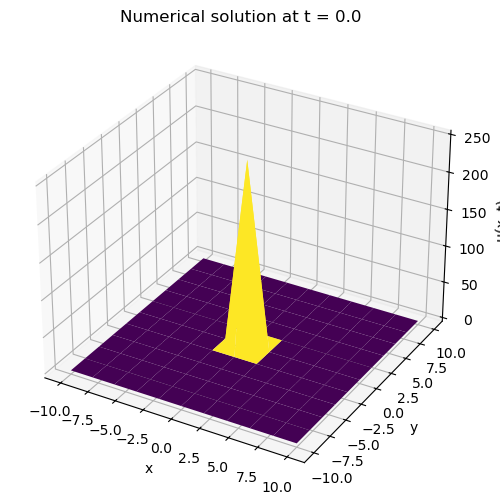

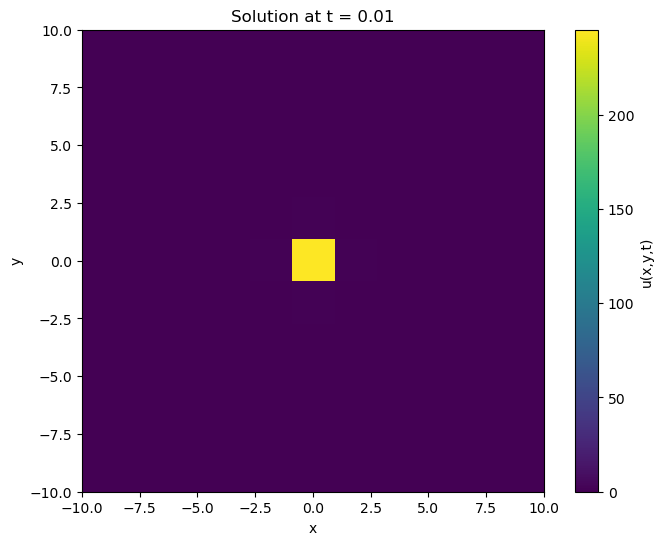

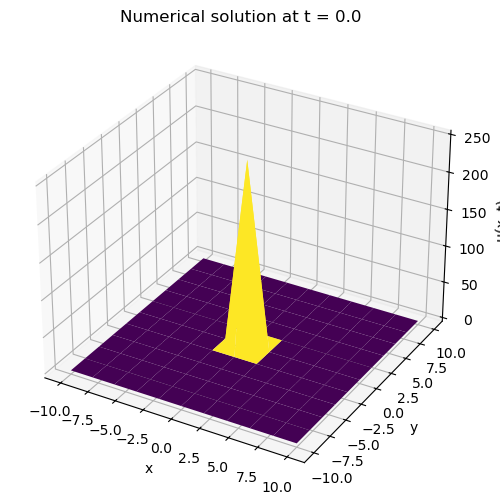

In [34]:
d=5
D, mass = 2.0, 1000
Lx, Ly = 10, 10
u, x, y, t = solve_forward_2D(D, mass, Lx, Ly, T=200, N=20000, density = 1, plot_at_t = 1)

plotting(t, x, y, u, 200)



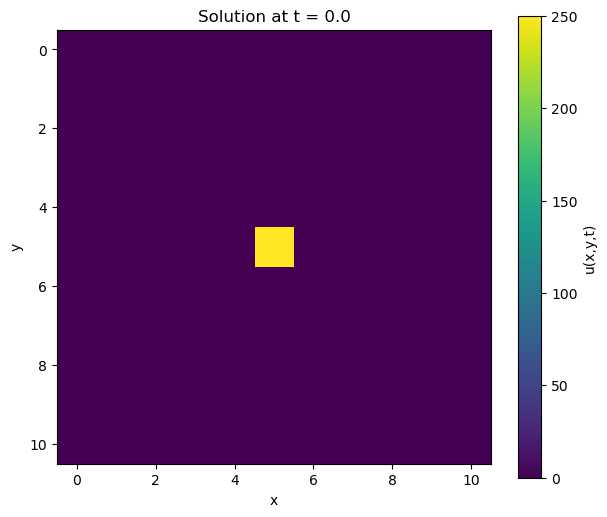

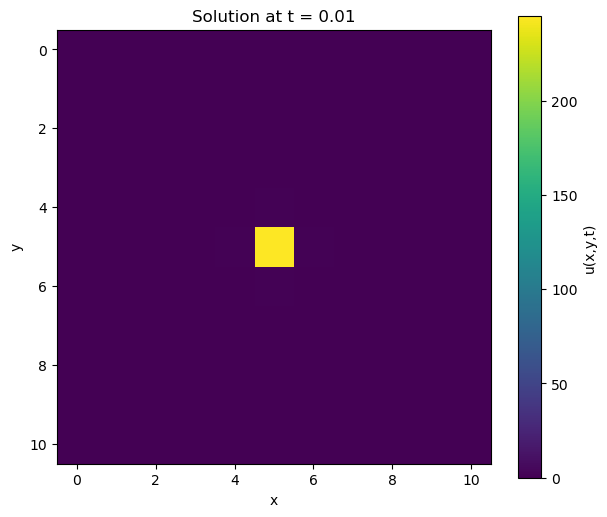

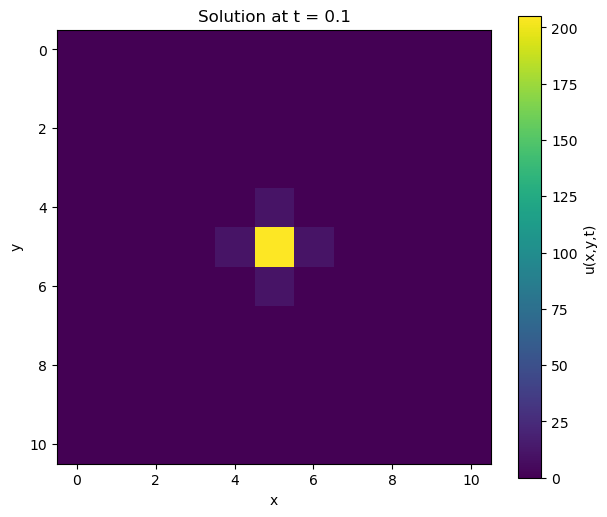

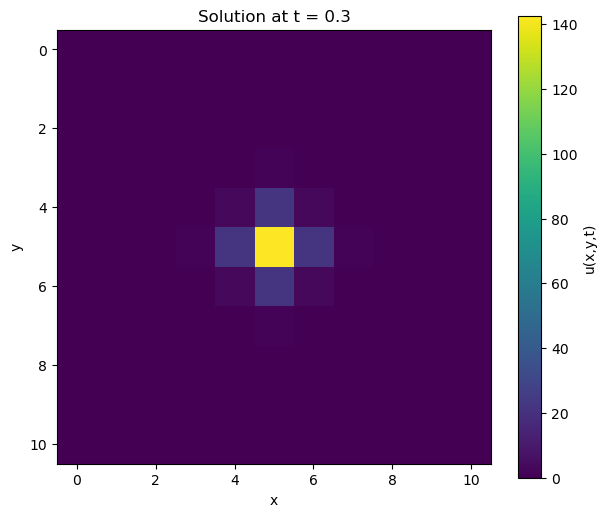

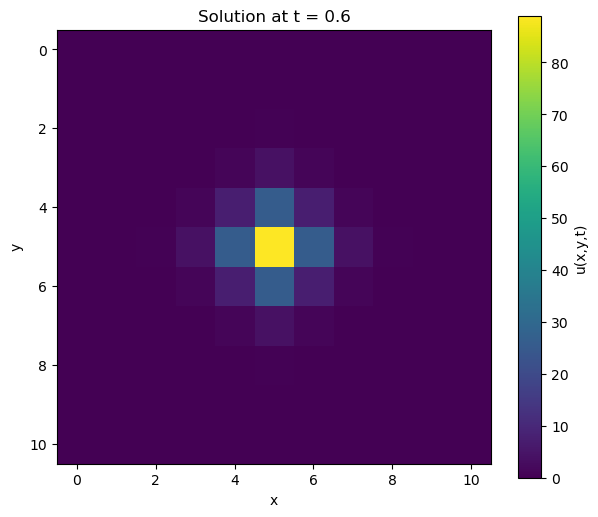

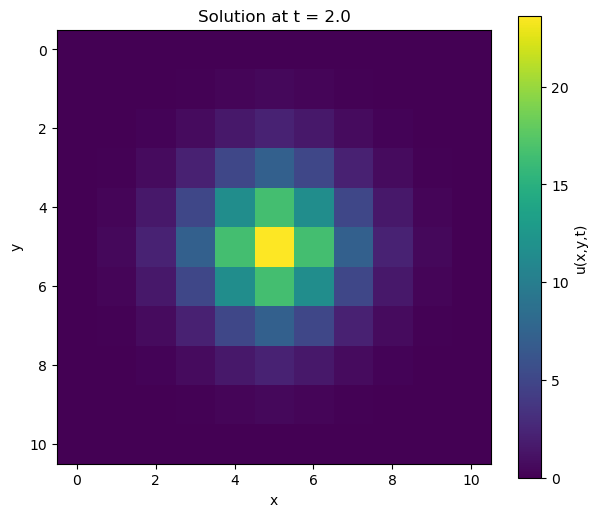

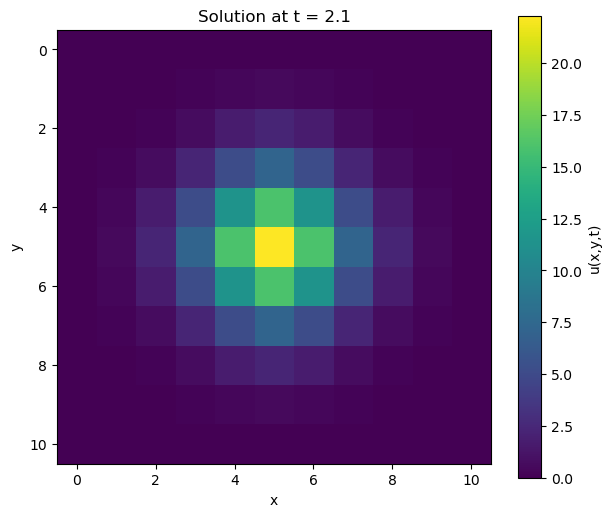

In [33]:
times = [0, 1, 10, 30, 60, 200, 210]
for k in times:

    plt.figure(figsize=(7, 6))

    plt.imshow(
        u[k, :, :].T,
        cmap='viridis'
    )

    plt.colorbar(label='u(x,y,t)')
    plt.title(f'Solution at t = {t[k]}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.show()